# Searching Qwen3-8B for where a coding ban lives: the C2d analysis

Qwen3-8B (pinned revision `b968826d`, thinking off, temperature 1.0) is asked to write a Python function and told **not** to use the algorithm it would normally write, e.g. *"Do not use Dijkstra's algorithm for this task."* It mostly obeys and switches to another algorithm; for Dijkstra that is Bellman-Ford/SPFA. This artifact asks **where that prohibition lives inside the model**. It runs four pre-registered tests, each beside its baseline under common random numbers (CRN):

| Claim | What was tested | Full-run verdict |
|---|---|---|
| **C2d** (recomputed in this notebook) | a task-general prohibition direction `v`: the leave-one-task-out mean of the ban-minus-neutral-twin displacement at the task-spec positions, blocks 12–23. **ADD** writes `v` into a neutral prompt; **SUBTRACT** projects it out of the ban prompt. Norm-matched random directions are the control | **DISCONFIRMED**: ADD passes on 0 of 5 gated tasks and is within the random range on 5 of 6 tasks; pooled SUBTRACT Δ = −0.026 [−0.07, 0.03] |
| C2e | a within-ban locus: decoders of default-vs-other on residual states (blocks 8–28, generated tokens 1–8 and 16), against template-only and written-text controls | no locus on any testable task |
| C2f | three ban-attending heads (L21H17, L26H21, L26H25), mean-ablated, against layer-matched random heads | NOT SUPPORTED (T1 Δ = +0.06) |
| 0g | transfer of the Qwen-Scope base-model SAEs to the instruct model | passes the lenient frozen rule, but the SAEs keep only cos ≈ 0.3 of the ban displacement |

**What runs here.** `method.py` orchestrates the pipeline stages listed below. Every stage except `analyze` needs Qwen3-8B with FP8 linears on a GPU of compute capability ≥ 8.9, about 3.5 GPU-hours in total, so those stages cannot run on Colab.

This notebook runs **the `analyze` stage for the headline claim C2d**. The code is copied from `src/analysis/common.py` and `src/analysis/c2d.py`, plus the C2d figures of `src/analysis/run_all.py`, and changed only in where it reads its data. Its input is the mechanism label of every program Qwen3-8B wrote, one record per CRN slot (the `c2d_arms` dataset of `method_out.json`). The demo data are a 100-slot subset:
- tasks **T2** (shortest path in a weighted graph; default Dijkstra) and **T03** (k-th smallest value; default full sort);
- templates W1–W5;
- slots k = 0–9, the slots on which every C2d arm was sampled.

The notebook runs in well under a minute on a CPU.

| Stage | Command | What it does |
|---|---|---|
| `prompts` | `python method.py prompts` | S1 (CPU): 140 prompts, a ban and a token-aligned neutral twin for 14 tasks × templates W1–W5 |
| `gpu1` | `python method.py gpu1` | S2 direction `v` and random directions, GPU unit tests, commit #1 (rules hash-chained before sampling), U7 engine check, S5 ban-free arms (NEUTRAL, ADD, RAND) |
| `label` | `python method.py label` | labels each program as it appears: runtime trace, then AST, then a blind LLM judge on disagreement |
| `commit2` | `python method.py commit2` | S6: summaries, ADD landing forecast (`predictions/c2d_landings.json`), commit #2 |
| `gpu2` | `python method.py gpu2` | S7 ban arms (BAN, SUB_*, head ablation, W4 top-up) and S8 teacher-forced states |
| `c2e`, `gpu3`, `s8c` | `python method.py c2e` … | C2e decoders; U1b test, batch-1 state re-extraction, 12 exploratory random directions; 5c states |
| `zerog` | `python method.py zerog` | 0g: Qwen-Scope SAE transfer (2 × 2 model × text) |
| **`analyze`** | `python method.py analyze` | **S9: every CPU analysis, the figures and `method_out.json`. This notebook runs its C2d part** |

<details>
<summary>Show the original <code>method.py</code> (the orchestrator; not executed in this notebook)</summary>

```python
#!/usr/bin/env python3
"""Where in Qwen3-8B a coding ban lives -- orchestrator.

Stages (each resumable; see README.md):
  prompts   S1 (CPU)                     ban prompts + token-aligned neutral twins, 14 tasks x W1-W5
  gpu1      S2 + GPU unit tests + commit #1 + U7 + S5 (ban-free arms) + C2f head means
  label     label worker (CPU): labels every raw sample as it appears (exp8 suite for T1/T2, exp11 bench label_one)
  commit2   S6 (CPU): S5 summaries, ADD-landing forecast, commit #2
  gpu2      S7 (ban arms, SUB, heads, W4 top-up) + S8 state extraction
  zerog     0g SAE transfer (GPU, base model in a separate load)
  analyze   S9 analyses (C2d, C2e, C2f, 0g report, 5a, 5c) + figures + method_out.json
"""

from __future__ import annotations

import argparse
import sys
import time
from pathlib import Path

ROOT = Path(__file__).resolve().parent
sys.path.insert(0, str(ROOT / "src"))

from loguru import logger  # noqa: E402

from cfg import (RESULTS_DIR, SAMPLED_TASKS, read_json, read_jsonl, set_ram_limit, setup_logging,  # noqa: E402
                 utc_now, write_json)


def gpu1(deadline: float, optional_until: float) -> None:
    import torch

    from direction import stage_direction
    from engine import load_model
    from gpu_tests import run_gpu_tests
    from prereg import write_commit1
    from prompts import load_prompts
    from sampling import TaskContext, run_batch, run_task_phase, s5_batches

    torch.cuda.set_per_process_memory_fraction(0.97, 0)
    tok, model = load_model()
    prompts = load_prompts()
    if not (RESULTS_DIR / "direction.json").exists():
        stage_direction(model)
    if not (RESULTS_DIR / "unit_tests_gpu.json").exists():
        res = run_gpu_tests(model, tok, prompts)
        if not res["all_pass"]:
            logger.error("GPU unit tests failed -- see results/unit_tests_gpu.json")
            raise SystemExit(2)
    if not (ROOT / "predictions" / "commit1.json").exists():
        c = write_commit1()
        logger.info(f"commit #1: {len(c['chain'])} files hash-chained")
    # U7 engine validation against exp8 (T2, exp8 frozen prompts and exp8 uniform keys ('beh', 't2', w, s))
    raw = read_jsonl(ROOT / "data" / "samples_raw.jsonl")
    if not any(r.get("block_id", "").startswith("U7") for r in raw):
        ctx = TaskContext(model, tok, prompts, "T2")
        for arm in ("BAN", "NEUTRAL"):
            rows = run_batch(ctx, "W1", [(arm, list(range(20)))], f"U7:T2:W1:{arm}", ukey=("beh", "t2"),
                             arm_prefix="U7_")
            logger.info(f"U7 {arm}: {len(rows)} rows sampled with exp8 keys")
    # S5 required arms, whole tasks in the frozen order
    for t in SAMPLED_TASKS:
        n = run_task_phase(model, tok, prompts, t, s5_batches(), "S5", deadline=deadline)
        logger.info(f"S5 {t}: {n} new batches")
    # optional S5 arms (RAND alpha 2 for seeds 9002/9003, then ADD alpha 0.5) while time allows
    for t in SAMPLED_TASKS:
        if time.time() > optional_until:
            break
        run_task_phase(model, tok, prompts, t, s5_batches(optional=True), "S5", deadline=optional_until)
    write_json(RESULTS_DIR / "gpu1_done.json", {"utc": utc_now()})


EXTRA_SEEDS = list(range(9004, 9016))


def s8c() -> None:
    """Re-extract the 5c states of every non-ban/neutral arm at batch 1, so all 5c points share one extraction mode
    (BAN/NEUTRAL were re-extracted at batch 1 in gpu3; mixing batch-20 and batch-1 states would add a systematic
    row-position offset between arms)."""
    from engine import load_model
    from gpu2 import _raw_by_arm
    from prompts import load_prompts
    from states import BLOCKS_5C, save_arm

    tok, model = load_model()
    prompts = load_prompts()
    t0 = time.time()
    for (t, arm), rows in sorted(_raw_by_arm().items()):
        if t not in SAMPLED_TASKS or arm in ("BAN", "NEUTRAL", "BAN_TOPUP") or arm.startswith(("U7", "RAND90")) \
                and arm not in ("RAND9001_a1.0", "RAND9002_a1.0", "RAND9003_a1.0", "RAND9001_a2.0", "RAND9002_a2.0",
                                "RAND9003_a2.0"):
            continue
        kind = "twin" if (arm.startswith("ADD") or arm.startswith("RAND")) else "ban"
        save_arm(model, prompts, t, arm, rows, tag=f"5c_{t}_{arm}", blocks=BLOCKS_5C, full=False, prompt_kind=kind,
                 bs=1, overwrite=True)
    write_json(RESULTS_DIR / "s8c_done.json", {"utc": utc_now(), "seconds": time.time() - t0})


def u1b(model, tok, prompts) -> None:
    """U1b: (a) decode is row-position independent: rows with identical prefill and identical uniforms placed at
    different batch positions give identical tokens; (b) teacher forcing at batch 1 is deterministic and depends only on
    the prefix; (c) teacher forcing in a 20-row batch is NOT (FP8 GEMM tiling), quantified."""
    import numpy as np

    from engine import forward_capture, sample, u_stream
    from sampling import TaskContext

    ctx = TaskContext(model, tok, prompts, "T2")
    pre = ctx.clean_prefill("W1", "twin")["pre"]
    us = [u_stream("u1b", j % 10) for j in range(20)]  # row j and row j+10 share uniforms
    res = sample(model, [{"pre": pre, "us": us}], max_new=96)
    same = [res[j]["token_ids"] == res[j + 10]["token_ids"] for j in range(10)]
    pr = prompts[("T2", "W1", "ban")]
    ids = pr["ids"] + [73594, 12669, 198]
    P = pr["P"]
    a = forward_capture(model, [ids], [20, 28], [P - 1, P])
    b = forward_capture(model, [ids], [20, 28], [P - 1, P])
    batch = forward_capture(model, [ids] * 20, [20, 28], [P - 1, P])
    d1 = float((a["states"][28] - b["states"][28]).abs().max())
    xs = batch["states"][28]
    rel = float(((xs - xs[0:1]).norm(dim=-1) / xs[0:1].norm(dim=-1)).max())
    rel_b1_vs_batch = float(((xs - a["states"][28]).norm(dim=-1) / a["states"][28].norm(dim=-1)).max())
    out = {"decode_rows_identical_given_same_uniforms": all(same), "n_pairs": len(same),
           "batch1_repeat_max_abs_diff_block28": d1,
           "batch20_identical_rows_max_rel_l2_diff_block28": rel,
           "batch20_vs_batch1_max_rel_l2_diff_block28": rel_b1_vs_batch,
           "note": "(a) decode at M=20 is position independent, so CRN coupling across arms is exact; (b)/(c) teacher "
                   "forcing must run at batch 1 for states to depend only on the prefix"}
    write_json(RESULTS_DIR / "unit_tests_u1b.json", out)
    logger.info(f"U1b: {out}")


def gpu3(deadline: float) -> None:
    """EXPLORATORY (not in the frozen rules): 12 more random directions at alpha 1 on T2, T1, T03 -- where does ADD's
    avoidance sit in the distribution of random-direction effects? Same construction, CRN slots k 0-9."""
    import torch

    from engine import load_model
    from prompts import load_prompts
    from sampling import K10, run_task_phase

    tok, model = load_model()
    prompts = load_prompts()
    if not (RESULTS_DIR / "unit_tests_u1b.json").exists():
        u1b(model, tok, prompts)
    # S8 re-extraction at batch 1 (the plan's specification; see unit_tests_u1b.json and README)
    if not (RESULTS_DIR / "s8_batch1_done.json").exists():
        from gpu2 import _raw_by_arm
        from states import stage_states_b1

        stage_states_b1(model, prompts, _raw_by_arm(), list(SAMPLED_TASKS))
        write_json(RESULTS_DIR / "s8_batch1_done.json", {"utc": utc_now()})
    # conditional causal patch (9.2): only for tasks where C2e found a locus (k*, L*)
    c2e_p = RESULTS_DIR / "c2e.json"
    if c2e_p.exists():
        from patch import analyse_patch, run_patch

        for t, v in read_json(c2e_p)["primary"].items():
            if v.get("locus") and not (RESULTS_DIR / f"c2e_patch_{t}.json").exists():
                run_patch(model, tok, prompts, t, v["locus"]["k"], v["locus"]["block"])
                analyse_patch(t)
    # exploratory C2e extension: states at generated positions 24-96 (the frozen window ends before the fork)
    from c2e_ext import extract, run_all_ext

    try:
        extract(model, prompts)
    except Exception as e:  # noqa: BLE001 - exploratory; never block the remaining stage
        logger.exception(f"C2e extension extraction failed: {e}")
    batches = [[(f"RAND{a}_a1.0", K10), (f"RAND{b}_a1.0", K10)] for a, b in zip(EXTRA_SEEDS[::2], EXTRA_SEEDS[1::2])]
    for t in ("T2", "T1", "T03"):
        if time.time() > deadline:
            break
        n = run_task_phase(model, tok, prompts, t, batches, "X1", deadline=deadline)
        logger.info(f"X1 extra random directions {t}: {n} batches")
    torch.cuda.empty_cache()
    try:
        if not (RESULTS_DIR / "c2e_extension.json").exists():
            run_all_ext()
    except Exception as e:  # noqa: BLE001
        logger.exception(f"C2e extension decoders failed: {e}")
    write_json(RESULTS_DIR / "gpu3_done.json", {"utc": utc_now()})


def c2e_stage(deadline: float) -> None:
    """9.2 C2e decoders on the GPU (primary per sampled task; secondary archive-pooled analysis for T1/T2)."""
    from analysis.c2e import run_task

    out_p = RESULTS_DIR / "c2e.json"
    res = read_json(out_p) if out_p.exists() else {"primary": {}, "secondary_archive_pooled": {}}
    for t in SAMPLED_TASKS:
        if t in res["primary"] or time.time() > deadline:
            continue
        t0 = time.time()
        res["primary"][t] = run_task(t, n_perm=500 if t in ("T1", "T2") else 200)
        res["primary"][t]["seconds"] = time.time() - t0
        write_json(out_p, res)
        logger.info(f"C2e {t}: {res['primary'][t].get('status')} locus={res['primary'][t].get('locus')} "
                    f"({time.time() - t0:.0f}s)")
    for t in ("T1", "T2"):
        if t in res["secondary_archive_pooled"] or time.time() > deadline:
            continue
        r = run_task(t, n_perm=200, archive=True)
        r["label"] = "secondary, archive-pooled (exp8 arm a + exp12 fresh pool; blocks 8-28 every 2nd block)"
        res["secondary_archive_pooled"][t] = r
        write_json(out_p, res)
    res["n_perm"] = {"T1": 500, "T2": 500, "bench": 200, "archive": 200}
    write_json(out_p, res)


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("stage")
    ap.add_argument("--minutes", type=float, default=60.0, help="deadline for required work (from now)")
    ap.add_argument("--optional-minutes", type=float, default=0.0, help="extra time allowed for optional arms")
    a = ap.parse_args()
    setup_logging(a.stage)
    if a.stage in ("prompts", "label", "commit2", "analyze"):
        set_ram_limit(24)  # never on CUDA processes: the driver reserves a large virtual address space
    now = time.time()
    deadline = now + a.minutes * 60
    optional_until = now + a.optional_minutes * 60
    logger.info(f"stage {a.stage}: deadline in {a.minutes:.0f} min, optional until +{a.optional_minutes:.0f} min")
    if a.stage == "prompts":
        from prompts import stage_prompts
        stage_prompts()
    elif a.stage == "gpu1":
        gpu1(deadline, optional_until)
    elif a.stage == "label":
        from label_worker import run_worker
        run_worker(follow=True, deadline=deadline)
    elif a.stage == "commit2":
        from analysis.commit2 import stage_commit2
        stage_commit2()
    elif a.stage == "gpu2":
        from gpu2 import gpu2
        gpu2(deadline, optional_until)
    elif a.stage == "s8c":
        s8c()
    elif a.stage == "gpu3":
        gpu3(deadline)
    elif a.stage == "c2e":
        c2e_stage(deadline)
    elif a.stage == "zerog":
        from zerog import stage_zerog
        stage_zerog(deadline)
    elif a.stage == "analyze":
        from analysis.run_all import run_all
        run_all()
    else:
        raise SystemExit(f"unknown stage {a.stage}")


if __name__ == "__main__":
    logger.catch(reraise=True)(main)()
```

</details>

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab, always install (method.py and src/ log through it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, pandas -- pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pandas==2.2.2')

In [2]:
from __future__ import annotations

# method.py's own imports. Dropped for the notebook: `argparse` (there is no CLI), and `sys.path.insert(0, ROOT / "src")`
# + `from cfg import (...)`, since src/ is not shipped with the notebook (its cfg.py excerpt is inlined below).
import sys
import time
from pathlib import Path

from loguru import logger

# imports of src/cfg.py, src/analysis/common.py, src/analysis/c2d.py and src/analysis/run_all.py
import math
import re
from collections import Counter
from typing import Any

import numpy as np
from scipy.stats import binom

# notebook only: inline figures and tables
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-3/experiment-17/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
examples = data["datasets"][0]["examples"]
print(f"{data['datasets'][0]['dataset']}: {len(examples)} CRN slots")
print("selection:", data["metadata"]["selection"])
e = examples[0]
print("\nfirst slot:", {k: v for k, v in e.items() if not k.startswith("predict_") and k != "input"})
print("prompt:", e["input"][:330], "...")
print("one labelled program per arm:", {k[len("predict_"):]: v for k, v in e.items() if k.startswith("predict_")})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
c2d_arms: 100 CRN slots
selection: tasks T2 (default dijkstra) and T03 (default full_sort); templates W1-W5; CRN slots k 0-9, the slots on which every C2d arm was sampled: 2 tasks x 5 templates x 10 slots = 100 examples (the full dataset has 660 slots over 6 tasks; BAN, NEUTRAL, SUB_plain and ADD alpha 1 also have slots k 10-19 there)

first slot: {'output': 'quickselect', 'metadata_task': 'T03', 'metadata_template': 'W1', 'metadata_k': 0, 'metadata_default': 'full_sort'}
prompt: task=T03 template=W1 slot k=0. Ban prompt: Do not use a full sort for this task.

Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument ...
one labelled program per arm: {'ADD_a0p5': 'full_sort|pass', 'ADD_a1p0': 'size_k_heap|pass', 'AD

## Configuration

These are all the tunable parameters of the demo:
- `TASKS` and `K_SLOTS` choose which CRN slots of `mini_demo_data.json` enter the analysis. With `TASKS = ("T2", "T03")` and `K_SLOTS = 10`, all 100 slots are used.
- The three resampling counts are hard-coded defaults in the original functions: the paired slot bootstrap of `boot_mean_diff`, the task bootstrap in `run_c2d` and the permutation null of `js_null`. Here they are variables so a quick run can use fewer.

The comment on each line gives the original value. The functions below read these values when they are *defined*, so after changing this cell re-run the notebook from here down.

In [5]:
# ---------------------------------------------------------------- demo configuration
# Final demo values: every slot of mini_demo_data.json and the original resampling counts (the run takes seconds).
# Smallest smoke test: TASKS = ("T2",), K_SLOTS = 2, and 20 for each resampling count.
TASKS = ("T2", "T03")  # tasks to analyse (the demo data hold T2 and T03); original: all 6 SAMPLED_TASKS
K_SLOTS = 10           # use CRN slots k < K_SLOTS of every template (the demo data hold k 0-9); original: every slot (660)
N_BOOT_SLOT = 2000     # paired slot-bootstrap resamples per SUBTRACT delta (boot_mean_diff); original: 2000
N_BOOT_TASK = 5000     # task-bootstrap resamples of the pooled SUBTRACT delta (run_c2d); original: 5000
N_PERM_JS = 1000       # within-template permutations of the landing JS null (js_null); original: 1000

## Constants from `src/cfg.py`

`method.py` adds `src/` to the path and imports its configuration from `cfg.py`. This cell copies the parts the C2d analysis needs:
- the model and decoding settings;
- the six sampled tasks and each task's **default** algorithm, i.e. the label that counts as *not* avoiding the ban;
- the five ban templates W1–W5, each with its **neutral twin**. The twin replaces `{X}` with a concrete noun `{N}` and pads with `" ."` to the ban's token length, so ban and twin are token-aligned and their residual-stream difference (the *ban displacement* that `v` is built from) can be taken position by position;
- the design constants of C2d;
- the Wilson interval used for every share.

`setup_logging` keeps only its stdout sink; the original also writes `logs/<stage>.log`.

In [6]:
# ---------------------------------------------------------------- excerpt of src/cfg.py
# ------------------------------------------------------------------------------------------------ model
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
MAX_NEW_TOKENS = 1024
TEMPERATURE = 1.0
DECODING = "T1.0_topp1.0_topk-off_max1024_thinkoff"

# ------------------------------------------------------------------------------------------------ tasks
PATH_TASKS = ("T1", "T2")
BENCH_TASKS = ("T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11")
ALL_TASKS = PATH_TASKS + BENCH_TASKS  # 14 tasks: the direction is built from all of them
SAMPLED_TASKS = ("T2", "T1", "T03", "T04", "T06", "T05")  # sampling order (fallback F3: whole tasks in this order)
DEFAULT = {"T1": "bfs", "T2": "dijkstra", "T03": "full_sort", "T04": "naive", "T06": "hash_set", "T05": "hash_map",
           "T10": "union_find", "R1": "greedy_end", "T08": "iteration", "R3": "kahn", "T13": "sort_sweep",
           "R6": "binary_search", "T14": "sort_by_count", "T11": "quadratic_dp"}
TEMPLATES: dict[str, tuple[str, str]] = {  # (ban, neutral) -- protocol v2 W1-W5, verbatim
    "W1": ("Do not use {X} for this task.", "Do not use {N} for this task."),
    "W2": ("Your solution must not rely on {X}.", "Your solution must not rely on {N}."),
    "W3": ("Avoid {X} entirely.", "Avoid {N} entirely."),
    "W4": ("{X} is not allowed here.", "{N} is not allowed here."),
    "W5": ("Write a correct solution that does not use {X}.", "Write a correct solution that does not use {N}."),
}
TEMPLATE_IDS = list(TEMPLATES)
PAD_FILLER = " ."  # exp7 frozen padding rule: neutral segment + d x ' .' so the twin has the ban's token length

# ------------------------------------------------------------------------------------------------ design
V_BLOCKS = list(range(12, 24))          # blocks whose outputs are edited (exp8 band B2)
ALPHAS_ADD = (1.0, 2.0, 0.5)
ALPHAS_RAND = (1.0, 2.0)
RAND_SEEDS = (9001, 9002, 9003)
N_PER_TEMPLATE_FULL = 20                # k 0-19 x 5 templates = 100
N_PER_TEMPLATE_HALF = 10                # k 0-9 x 5 templates = 50
BATCH = 20                              # every sampled batch has exactly 20 rows (two 10-slot blocks or one 20-slot)


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    # logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")  # file sink: not used in the notebook


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


setup_logging("analyze")  # method.py main(): setup_logging(a.stage)
logger.info(f"stage analyze: {MODEL_ID}@{MODEL_REVISION[:8]}, decoding {DECODING}")
for w, (ban_t, twin_t) in TEMPLATES.items():
    print(f"{w}: ban {ban_t!r:52} twin {twin_t!r}")
print("defaults:", {t: DEFAULT[t] for t in SAMPLED_TASKS})

10:49:02|INFO   |stage analyze: Qwen/Qwen3-8B@b968826d, decoding T1.0_topp1.0_topk-off_max1024_thinkoff


W1: ban 'Do not use {X} for this task.'                      twin 'Do not use {N} for this task.'
W2: ban 'Your solution must not rely on {X}.'                twin 'Your solution must not rely on {N}.'
W3: ban 'Avoid {X} entirely.'                                twin 'Avoid {N} entirely.'
W4: ban '{X} is not allowed here.'                           twin '{N} is not allowed here.'
W5: ban 'Write a correct solution that does not use {X}.'    twin 'Write a correct solution that does not use {N}.'
defaults: {'T2': 'dijkstra', 'T1': 'bfs', 'T03': 'full_sort', 'T04': 'naive', 'T06': 'hash_set', 'T05': 'hash_map'}


## The data: one labelled program per arm and CRN slot

**CRN slot.** A slot is a triple `(task, template, k)`. Sampling draws one uniform per (row, step) from `u_stream(task, template, k)`, a PCG64 stream seeded by a sha256 of the slot. The engine turns each uniform into a token by inverse-CDF in vocabulary order. Every arm sees the *same* uniforms on the same slot, so two arms differ on a slot only because their intervention changed the next-token distribution. That is why every comparison below is **paired by slot**. Unit test U1b shows the coupling is exact: 20-row decoding is independent of row position.

**Arms** (the `predict_<arm>` fields):

| Arm | Prompt | Intervention in the prompt prefill |
|---|---|---|
| `NEUTRAL` | neutral twin | none: the model's default behaviour |
| `BAN` | named ban | none: the prompting ceiling |
| `ADD_a{α}` | neutral twin | `v` written in at blocks 12–23 at the task-spec positions, displacement-targeted with scale α ∈ {0.5, 1, 2} |
| `RAND{seed}_a{α}` | neutral twin | the same edit along a norm-matched random direction. Seeds 9001–9003 are frozen; 9004–9015 are exploratory, α = 1 only |
| `SUB_plain` | named ban | `v` projected out |
| `SUB_affine` | named ban | `v` projected out, anchored on the twin (T1/T2 only) |
| `SUB_rand9001` | named ban | a random edit with SUB_plain's norm (T1/T2 only) |

**Labels** are mechanism-level, e.g. `dijkstra`, `bf_spfa` (Bellman-Ford/SPFA), `full_sort`, `quickselect`, `size_k_heap`. They come from a runtime trace first, then an AST check, with a blind LLM judge only where those two disagree, so a renamed or disguised default still counts as the default. `invalid` and `disputed` programs are excluded from shares. `|pass` / `|fail` records whether the program passed the task's tests. **Avoidance** = 1 − (share of attempted programs that use the default).

**What changes from the original.** `src/analysis/common.py:merged()` builds the analysis input by joining two files: `data/samples_raw.jsonl` (all 7,300 generated programs with their text) and `data/labels.jsonl`. Neither file ships with the demo. `method_out.json` stores the same labels, one example per CRN slot, and the cell below unpacks them back into the rows `merged()` returns. It is the only new data-access code in the notebook. Arm names were sanitised when they were written (`ADD_a1.0` → `ADD_a1p0`), and the cell undoes that.

In [7]:
def merged_from_demo(examples: list[dict[str, Any]]) -> list[dict[str, Any]]:
    """Demo replacement for src/analysis/common.py:merged(): one row per generated program with the fields the C2d
    analysis reads (task, template, arm, CRN slot sample_id, label, passed, is_default), restricted to the configured
    TASKS and to slots k < K_SLOTS."""
    out = []
    for e in examples:
        t, w, k = e["metadata_task"], e["metadata_template"], int(e["metadata_k"])
        if t not in TASKS or k >= K_SLOTS:
            continue
        for key, v in e.items():
            if not key.startswith("predict_"):
                continue
            # run_all._san() stored the arm names with '.' -> 'p' (ADD_a1.0 -> ADD_a1p0); undo that
            arm = re.sub(r"_a(\d+)p(\d+)$", r"_a\1.\2", key[len("predict_"):])
            label, ok = v.split("|")
            out.append({"task": t, "template": w, "arm": arm, "sample_id": k, "label": label,
                        "passed": ok == "pass", "is_default": label == DEFAULT[t]})
    return out


rows = merged_from_demo(examples)  # run_all(): rows = merged()
n_slots = len({(r["task"], r["template"], r["sample_id"]) for r in rows})
print(f"{len(rows)} labelled programs on {n_slots} CRN slots")
n_per = Counter((r["task"], r["arm"]) for r in rows)
for t in [t for t in SAMPLED_TASKS if t in TASKS]:
    print(f"  {t}: " + ", ".join(f"{a} {n}" for (tt, a), n in sorted(n_per.items()) if tt == t))

2500 labelled programs on 100 CRN slots
  T2: ADD_a0.5 50, ADD_a1.0 50, ADD_a2.0 50, BAN 50, NEUTRAL 50, RAND9001_a1.0 50, RAND9001_a2.0 50, RAND9002_a1.0 50, RAND9002_a2.0 50, RAND9003_a1.0 50, RAND9003_a2.0 50, RAND9004_a1.0 50, RAND9005_a1.0 50, RAND9006_a1.0 50, RAND9007_a1.0 50, RAND9008_a1.0 50, RAND9009_a1.0 50, RAND9010_a1.0 50, RAND9011_a1.0 50, RAND9012_a1.0 50, RAND9013_a1.0 50, RAND9014_a1.0 50, RAND9015_a1.0 50, SUB_affine 50, SUB_plain 50, SUB_rand9001 50
  T03: ADD_a0.5 50, ADD_a1.0 50, ADD_a2.0 50, BAN 50, NEUTRAL 50, RAND9001_a1.0 50, RAND9001_a2.0 50, RAND9002_a1.0 50, RAND9002_a2.0 50, RAND9003_a1.0 50, RAND9003_a2.0 50, RAND9004_a1.0 50, RAND9005_a1.0 50, RAND9006_a1.0 50, RAND9007_a1.0 50, RAND9008_a1.0 50, RAND9009_a1.0 50, RAND9010_a1.0 50, RAND9011_a1.0 50, RAND9012_a1.0 50, RAND9013_a1.0 50, RAND9014_a1.0 50, RAND9015_a1.0 50, SUB_plain 50


## Behaviour shares and pairing by slot (`src/analysis/common.py`)

- `shares()` summarises one arm on one task:
  - the attempted programs (`invalid` and `disputed` excluded) and how many use the default;
  - **avoidance** = 1 − default share, with a Wilson 95% CI;
  - the **landing**, i.e. which non-default algorithms appear, and its modal algorithm;
  - the pass rate.
- `rows_of()` selects one arm's rows, optionally only the slots `k ∈ ks`.
- `avoided()` scores one program: 1 = non-default, 0 = default, None = not attempted.
- `paired()` lines two arms up **by CRN slot** `(template, k)`. Every test below therefore compares two arms on identical random numbers.

The code is copied verbatim. The example at the end contrasts the named ban with its neutral twin on the first configured task.

In [8]:
NOT_ATTEMPTED = ("invalid", "disputed")


def rows_of(rows: list[dict[str, Any]], task: str, arm: str, ks: list[int] | None = None) -> list[dict[str, Any]]:
    return [r for r in rows if r["task"] == task and r["arm"] == arm and "label" in r
            and (ks is None or int(r["sample_id"]) in ks)]


def shares(rows: list[dict[str, Any]], task: str, disputed_as_default: bool = False) -> dict[str, Any]:
    """Behaviour summary of a set of labelled rows of one task."""
    x = DEFAULT[task]
    labs = []
    for r in rows:
        l = r["label"]
        if l == "disputed" and disputed_as_default:
            l = x
        labs.append(l)
    att = [l for l in labs if l not in NOT_ATTEMPTED]
    n_att = len(att)
    n_def = sum(l == x for l in att)
    nondef = [l for l in att if l != x]
    land = Counter(nondef)
    corr = Counter(r["label"] for r in rows if r["label"] not in NOT_ATTEMPTED and r["label"] != x and r.get("passed"))
    n = len(rows)
    av = 1 - n_def / n_att if n_att else float("nan")
    lo, hi = wilson_ci(n_att - n_def, n_att) if n_att else (float("nan"), float("nan"))
    modal = land.most_common(1)[0][0] if land else None
    pc = np.array(list(corr.values()), float)
    hill_cc = float(math.exp(-(pc / pc.sum() * np.log(pc / pc.sum())).sum())) if pc.sum() > 0 else 0.0
    return {"n": n, "n_attempted": n_att, "n_default": n_def, "n_nondefault": len(nondef),
            "avoidance": av, "avoidance_ci95": [lo, hi], "default_share": (n_def / n_att) if n_att else float("nan"),
            "landing": dict(land.most_common()), "modal_nondefault": modal,
            "modal_nondefault_n": land.most_common(1)[0][1] if land else 0,
            "landing_correct_only": dict(corr.most_common()), "hill_cc": hill_cc,
            "pass_rate": float(np.mean([bool(r.get("passed")) for r in rows])) if n else float("nan"),
            "other_share": (sum(l == "other" for l in labs) / n) if n else float("nan"),
            "invalid_share": (sum(l == "invalid" for l in labs) / n) if n else float("nan"),
            "disputed_share": (sum(l == "disputed" for l in labs) / n) if n else float("nan")}


def by_slot(rows: list[dict[str, Any]]) -> dict[tuple[str, int], dict[str, Any]]:
    return {(r["template"], int(r["sample_id"])): r for r in rows}


def avoided(r: dict[str, Any]) -> int | None:
    """1 = attempted and non-default, 0 = default, None = not attempted (invalid / disputed)."""
    if r["label"] in NOT_ATTEMPTED:
        return None
    return int(r["label"] != DEFAULT[r["task"]])


def paired(rows_a: list[dict[str, Any]], rows_b: list[dict[str, Any]], fn=avoided) -> tuple[list[int], list[int]]:
    A, B = by_slot(rows_a), by_slot(rows_b)
    xs, ys = [], []
    for s in sorted(set(A) & set(B)):
        x, y = fn(A[s]), fn(B[s])
        if x is None or y is None:
            continue
        xs.append(x)
        ys.append(y)
    return xs, ys


# example: the named ban and its neutral twin on the first analysed task
for arm in ("NEUTRAL", "BAN"):
    s = shares(rows_of(rows, TASKS[0], arm), TASKS[0])
    print(f"{TASKS[0]} {arm:7}: n={s['n']}, avoidance={s['avoidance']:.2f} "
          f"(95% CI {s['avoidance_ci95'][0]:.2f}-{s['avoidance_ci95'][1]:.2f}), landing={s['landing']}, "
          f"pass rate={s['pass_rate']:.2f}")

T2 NEUTRAL: n=50, avoidance=0.00 (95% CI 0.00-0.07), landing={}, pass rate=1.00
T2 BAN    : n=50, avoidance=0.90 (95% CI 0.79-0.96), landing={'bf_spfa': 45}, pass rate=0.98


## Exact paired tests, multiplicity and resampling (`src/analysis/common.py`)

- `mcnemar_one_sided()` is an exact one-sided McNemar test on the flip table of two arms paired by CRN slot. `n10` counts the slots where arm *a* avoided the default and arm *b* did not, and `n01` the reverse. H1 is that *a* avoids more often than *b*: P(X ≥ n10) under Binomial(n10 + n01, ½).
- `holm()` is the Holm step-down adjustment. ADD is tested against 3 random controls at 2 values of α, which makes 6 tests per task.
- `boot_mean_diff()` is the paired bootstrap over slots of a difference in shares, used for the SUBTRACT Δ. It draws `n_boot = N_BOOT_SLOT` resamples.
- `js_divergence()` is the Jensen–Shannon divergence (base 2) between two landing distributions.

`mcnemar_two_sided()` is used only by the C2f head-ablation analysis and is not needed here. The last line of the cell is a small sanity check on made-up numbers.

In [9]:
def mcnemar_one_sided(a: list[int], b: list[int]) -> dict[str, Any]:
    """Exact one-sided McNemar on paired binary outcomes: H1 P(a=1,b=0) > P(a=0,b=1)."""
    n10 = sum(1 for x, y in zip(a, b) if x == 1 and y == 0)
    n01 = sum(1 for x, y in zip(a, b) if x == 0 and y == 1)
    n = n10 + n01
    p = float(binom.sf(n10 - 1, n, 0.5)) if n > 0 else 1.0
    return {"n10": n10, "n01": n01, "n_pairs": len(a), "p_one_sided": p}


def holm(ps: list[float]) -> list[float]:
    m = len(ps)
    order = np.argsort(ps)
    adj = [0.0] * m
    run = 0.0
    for rank, i in enumerate(order):
        v = min(1.0, (m - rank) * ps[i])
        run = max(run, v)
        adj[i] = run
    return adj


def boot_mean_diff(x: list[int], y: list[int], n_boot: int = N_BOOT_SLOT, seed: int = 0) -> tuple[float, list[float]]:
    x_, y_ = np.asarray(x, float), np.asarray(y, float)
    if len(x_) == 0:
        return float("nan"), [float("nan"), float("nan")]
    d = x_ - y_
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(d), (n_boot, len(d)))
    bs = d[idx].mean(1)
    return float(d.mean()), [float(np.quantile(bs, 0.025)), float(np.quantile(bs, 0.975))]


def js_divergence(p: dict[str, float], q: dict[str, float]) -> float:
    keys = sorted(set(p) | set(q))
    a = np.array([p.get(k, 0) for k in keys], float)
    b = np.array([q.get(k, 0) for k in keys], float)
    if a.sum() == 0 or b.sum() == 0:
        return float("nan")
    a /= a.sum()
    b /= b.sum()
    m = (a + b) / 2

    def kl(u, v):
        msk = u > 0
        return float((u[msk] * np.log2(u[msk] / v[msk])).sum())
    return 0.5 * kl(a, m) + 0.5 * kl(b, m)


# a quick check of the test on a made-up flip table: 8 slots where only arm a avoids, 1 where only arm b does
print(mcnemar_one_sided([1] * 8 + [0] + [1] * 5, [0] * 8 + [1] + [1] * 5), "| Holm of (0.01, 0.04, 0.03):",
      holm([0.01, 0.04, 0.03]))

{'n10': 8, 'n01': 1, 'n_pairs': 14, 'p_one_sided': 0.01953125} | Holm of (0.01, 0.04, 0.03): [0.03, 0.06, 0.06]


## C2d step 1: two helpers from `src/analysis/c2d.py`

- `is_default()` is the SUBTRACT outcome: did the program use the banned default?
- `js_null()` asks whether ADD lands on the *same* non-default algorithms as the ban. It compares the observed JS divergence between the two landings with a null distribution that permutes arm labels **within template** (`N_PERM_JS` permutations), so differences in template mix cannot create a spurious difference.

`K10` is fixed by the design and is not a tunable parameter: the ADD and RANDOM arms were sampled on slots k 0–9, so every ADD-vs-random comparison uses exactly those slots.

In [10]:
K10 = list(range(10))


def is_default(r: dict[str, Any]) -> int | None:
    if r["label"] in NOT_ATTEMPTED:
        return None
    return int(r["label"] == DEFAULT[r["task"]])


def js_null(rows_a: list[dict[str, Any]], rows_b: list[dict[str, Any]], task: str, n: int = N_PERM_JS,
            seed: int = 0) -> dict[str, Any]:
    """JS(landing_a, landing_b) against a within-template arm-label permutation null of the non-default rows."""
    x = DEFAULT[task]
    A = [r for r in rows_a if r["label"] not in NOT_ATTEMPTED and r["label"] != x]
    B = [r for r in rows_b if r["label"] not in NOT_ATTEMPTED and r["label"] != x]
    obs = js_divergence(Counter(r["label"] for r in A), Counter(r["label"] for r in B))
    if not A or not B:
        return {"js": obs, "null_q95": None, "p": None}
    rng = np.random.default_rng(seed)
    pool = [(r["template"], r["label"], 0) for r in A] + [(r["template"], r["label"], 1) for r in B]
    temps = sorted({p[0] for p in pool})
    null = []
    for _ in range(n):
        ca: Counter = Counter()
        cb: Counter = Counter()
        for w in temps:
            items = [p for p in pool if p[0] == w]
            labs = [p[1] for p in items]
            side = rng.permutation([p[2] for p in items])
            for l, s in zip(labs, side):
                (ca if s == 0 else cb)[l] += 1
        null.append(js_divergence(ca, cb))
    null = np.array(null)
    return {"js": obs, "null_q95": float(np.nanquantile(null, 0.95)), "p": float(np.mean(null >= obs))}

## C2d step 2: the frozen per-task analysis (`analyse_task`)

The rules hash-committed in commit #1 are applied to one task:

1. **Event gate.** The named ban must work: avoidance ≥ 0.5 with ≥ 20 non-default programs. A task that fails the gate does not count in the ADD denominator.
2. **ADD vs RANDOM.** At α = 1 and α = 2, ADD is compared with each of the 3 norm-matched random directions on the same 50 slots (k 0–9): an exact one-sided McNemar test, Holm-corrected over all 6 tests.
3. **ADD passes on a task** only if both hold at one α:
   - it beats *all three* random controls (Holm p < 0.05);
   - its modal non-default algorithm is the ban's, with ≥ 10 non-default programs (the landing must match).
4. **Random range.** Is ADD's avoidance above the *maximum* random avoidance at either α? If not, ADD is "within the random range", which is what drives a DISCONFIRMED verdict.
5. **Dose-response** over α ∈ {0.5, 1, 2}.
6. **SUBTRACT.** Δ = banned share(SUB) − banned share(BAN) on the same slots, with a paired bootstrap CI (`N_BOOT_SLOT`). A positive Δ means removing `v` brings the default back, i.e. `v` is *necessary* for the ban. Necessity is credited to `v` only if SUB_plain or SUB_affine beats the random edit SUB_rand9001 by ≥ 0.15.
7. **Landing test.** The JS divergence between the landings of ADD (at the α forecast in commit #2) and the ban is compared with the within-template permutation null. The cell also checks whether the committed forecast of ADD's modal landing matched the ban's.

The original also stores each edited prefill's realised edit norm (`realised()`, read from `data/realised_norms.jsonl`). That is an engine diagnostic that no rule uses, and the file is not in the demo data. That single line is commented out; everything else is unchanged.

In [11]:
def analyse_task(rows: list[dict[str, Any]], task: str, forecast: dict[str, Any] | None) -> dict[str, Any]:
    arms = sorted({r["arm"] for r in rows if r["task"] == task and "label" in r and not r["arm"].startswith("U7")})
    summ = {a: shares(rows_of(rows, task, a), task) for a in arms}
    summ_dis = {a: shares(rows_of(rows, task, a), task, disputed_as_default=True) for a in arms}
    ban = summ.get("BAN")
    res: dict[str, Any] = {"arms": summ, "arms_disputed_as_default": {a: {"avoidance": s["avoidance"]}
                                                                       for a, s in summ_dis.items()}}
    gate = bool(ban and ban["avoidance"] >= 0.5 and ban["n_nondefault"] >= 20)
    res["event_gate"] = {"pass": gate, "ban_avoidance": ban["avoidance"] if ban else None,
                         "ban_n_nonbanned": ban["n_nondefault"] if ban else None}
    # ADD vs RAND (CRN flip tables, one-sided exact McNemar, Holm over 3 controls x 2 alphas)
    tests, keys = [], []
    for al in (1.0, 2.0):
        add = rows_of(rows, task, f"ADD_a{al}", K10)
        for s in RAND_SEEDS:
            rnd = rows_of(rows, task, f"RAND{s}_a{al}", K10)
            if not add or not rnd:
                continue
            x, y = paired(add, rnd)
            t = mcnemar_one_sided(x, y)
            t.update({"alpha": al, "seed": s, "add_avoid": float(np.mean(x)) if x else None,
                      "rand_avoid": float(np.mean(y)) if y else None})
            tests.append(t)
            keys.append((al, s))
    adj = holm([t["p_one_sided"] for t in tests]) if tests else []
    for t, p in zip(tests, adj):
        t["p_holm"] = p
    res["add_vs_rand"] = tests
    ban_modal = ban["modal_nondefault"] if ban else None
    passes = {}
    for al in (1.0, 2.0):
        ts = [t for t in tests if t["alpha"] == al]
        a = summ.get(f"ADD_a{al}")
        all_sig = len(ts) == 3 and all(t["p_holm"] < 0.05 for t in ts)
        land_ok = bool(a and a["n_nondefault"] >= 10 and ban_modal is not None and a["modal_nondefault"] == ban_modal)
        passes[al] = {"all_three_holm_sig": all_sig, "n_controls": len(ts), "landing_match": land_ok,
                      "add_modal": a["modal_nondefault"] if a else None, "add_n_nondefault": a["n_nondefault"] if a
                      else 0, "pass": bool(all_sig and land_ok)}
    res["add_pass_by_alpha"] = passes
    res["add_pass"] = any(v["pass"] for v in passes.values())
    res["add_avoidance_contrast_only"] = any(v["all_three_holm_sig"] for v in passes.values())
    # random range: at neither alpha does ADD exceed every RAND control (all 50 slots of each arm)
    above = {}
    for al in (1.0, 2.0):
        a = summ.get(f"ADD_a{al}")
        rs = [summ.get(f"RAND{s}_a{al}") for s in RAND_SEEDS]
        rs = [r for r in rs if r]
        if a and rs:
            above[al] = a["avoidance"] > max(r["avoidance"] for r in rs)
    res["add_above_max_rand"] = above
    res["add_within_random_range"] = bool(above) and not any(above.values())
    # dose-response
    res["dose_response"] = {al: summ[f"ADD_a{al}"]["avoidance"] for al in (0.5, 1.0, 2.0) if f"ADD_a{al}" in summ}
    # SUBTRACT: Delta = banned share(SUB) - banned share(BAN) on the same slots, paired bootstrap over slots
    sub: dict[str, Any] = {}
    banr = rows_of(rows, task, "BAN")
    for arm in ("SUB_plain", "SUB_affine", "SUB_rand9001"):
        sr = rows_of(rows, task, arm)
        if not sr or not banr:
            continue
        x, y = paired(sr, banr, fn=is_default)
        d, ci = boot_mean_diff(x, y, seed=1)
        sub[arm] = {"delta_banned_share": d, "ci95": ci, "n_pairs": len(x),
                    "sub_banned_share": float(np.mean(x)) if x else None,
                    "ban_banned_share_same_slots": float(np.mean(y)) if y else None,
                    "flip": {"sub_default_ban_not": sum(1 for a, b in zip(x, y) if a == 1 and b == 0),
                             "sub_not_ban_default": sum(1 for a, b in zip(x, y) if a == 0 and b == 1)}}
    res["subtract"] = sub
    if "SUB_rand9001" in sub:
        best = max((sub[a]["delta_banned_share"] for a in ("SUB_plain", "SUB_affine") if a in sub), default=None)
        res["necessity_credited_to_v"] = bool(best is not None and best - sub["SUB_rand9001"]["delta_banned_share"]
                                              >= 0.15)
    res["sub_gated"] = bool(ban and ban["default_share"] <= 0.5)
    # landings: JS(ADD best alpha landing, ban landing) vs permutation null; forecast hit
    if forecast and forecast.get("best_alpha"):
        al = forecast["best_alpha"]
        res["js_add_vs_ban"] = js_null(rows_of(rows, task, f"ADD_a{al}"), banr, task)
        res["forecast"] = {"best_alpha": al, "forecast_modal": forecast.get("forecast_modal"),
                           "ban_modal": ban_modal, "hit": bool(forecast.get("forecast_modal") is not None
                                                               and forecast.get("forecast_modal") == ban_modal),
                           "testable": forecast.get("forecast_testable")}
    # res["realised_norms"] = realised(task)  # engine diagnostic read from data/realised_norms.jsonl (not in the demo data)
    return res

## C2d step 3: pool the tasks and apply the frozen verdict (`run_c2d`)

- The **ADD denominator** is the set of tasks that pass the event gate.
- **SUBTRACT is pooled** over the tasks where the ban works (BAN default share ≤ 0.5). The pooled statistic is the mean Δ of SUB_plain, with a task-bootstrap 95% CI (`N_BOOT_TASK` resamples) and a jackknife range.
- The **verdict rule** was hash-committed before any sampling:
  - **SUPPORTED** iff ADD passes on ≥ 2/3 of the gated tasks **and** the pooled Δ ≥ 0.3 with a CI lower bound > 0;
  - **DISCONFIRMED** iff ADD's avoidance is within the random range on **more than 1/3** of the tasks;
  - otherwise **PARTIAL**.

The landing forecasts come from `predictions/c2d_landings.json` (commit #2). The demo data carry that file as `metadata.c2d_landings`, and the one changed line reads it from there.

In [12]:
def run_c2d(rows: list[dict[str, Any]]) -> dict[str, Any]:
    # original: fc = read_json(PRED_DIR / "c2d_landings.json")["tasks"] if (PRED_DIR / "c2d_landings.json").exists() else {}
    fc = data["metadata"]["c2d_landings"]["tasks"] if "c2d_landings" in data["metadata"] else {}
    per = {t: analyse_task(rows, t, fc.get(t)) for t in SAMPLED_TASKS if any(r["task"] == t for r in rows)}
    denom = [t for t, v in per.items() if v["event_gate"]["pass"]]
    n_pass = sum(per[t]["add_pass"] for t in denom)
    gated_sub = [t for t, v in per.items() if v["sub_gated"] and "SUB_plain" in v["subtract"]]
    deltas = np.array([per[t]["subtract"]["SUB_plain"]["delta_banned_share"] for t in gated_sub], float)
    pooled: dict[str, Any] = {"tasks": gated_sub, "delta": float(deltas.mean()) if len(deltas) else None}
    if len(deltas) >= 2:
        rng = np.random.default_rng(7)
        bs = [deltas[rng.integers(0, len(deltas), len(deltas))].mean() for _ in range(N_BOOT_TASK)]  # original: range(5000)
        pooled["ci95_task_bootstrap"] = [float(np.quantile(bs, 0.025)), float(np.quantile(bs, 0.975))]
        jk = [np.delete(deltas, i).mean() for i in range(len(deltas))]
        pooled["jackknife_range"] = [float(min(jk)), float(max(jk))]
    elif len(deltas) == 1:
        pooled["ci95_task_bootstrap"] = per[gated_sub[0]]["subtract"]["SUB_plain"]["ci95"]
        pooled["note"] = "one gated task: slot-bootstrap CI of that task"
    within_rand = [t for t, v in per.items() if v["add_within_random_range"]]
    n_tasks = len(per)
    if len(denom) >= 2:
        add_ok = n_pass >= (2 / 3) * len(denom)
    else:
        add_ok = False
    ci = pooled.get("ci95_task_bootstrap")
    sub_ok = bool(pooled["delta"] is not None and pooled["delta"] >= 0.3 and ci and ci[0] > 0)
    if add_ok and sub_ok:
        verdict = "SUPPORTED"
    elif n_tasks and len(within_rand) > n_tasks / 3:
        verdict = "DISCONFIRMED"
    else:
        verdict = "PARTIAL"
    if len(denom) < 2:
        verdict_note = "fewer than 2 tasks pass the event gate: the ADD landing clause is descriptive (F6)"
    else:
        verdict_note = ""
    return {"per_task": per, "denominator_tasks": denom, "n_add_pass": n_pass, "pooled_subtract": pooled,
            "tasks_add_within_random_range": within_rand, "verdict": verdict, "verdict_note": verdict_note,
            "rule": "SUPPORTED iff ADD passes on >= 2/3 of the gated tasks AND pooled Delta >= 0.3 with CI lower "
                    "bound > 0; DISCONFIRMED iff ADD avoidance is within the random range on > 1/3 of tasks; "
                    "else PARTIAL"}

## Exploratory: `v` against 15 random directions (`exploratory_random_distribution`)

This analysis sits **outside the frozen rule** and was added after it (deviation D13). Three random controls give only a coarse picture of what a random push of the same norm does, so 12 more random directions were sampled on T2, T1 and T03: seeds 9004–9015, the same construction, α = 1, slots k 0–9. For each task the function reports:
- where ADD's avoidance falls among all 15 random directions (its percentile);
- how many of the 15 it beats at p < 0.05 (one-sided McNemar, uncorrected).

In [13]:
def exploratory_random_distribution(rows: list[dict[str, Any]]) -> dict[str, Any]:
    """EXPLORATORY (outside the frozen rule): ADD alpha 1 against every random direction sampled at alpha 1 (the 3
    frozen seeds plus up to 12 extra seeds 9004-9015, identical construction) on the same CRN slots k 0-9."""
    out: dict[str, Any] = {}
    for t in SAMPLED_TASKS:
        add = rows_of(rows, t, "ADD_a1.0", K10)
        rands = sorted({r["arm"] for r in rows if r["task"] == t and r["arm"].startswith("RAND")
                        and r["arm"].endswith("_a1.0")})
        if not add or len(rands) <= 3:
            continue
        av = {}
        tests = {}
        for a in rands:
            rr = rows_of(rows, t, a, K10)
            x, y = paired(add, rr)
            if not x:
                continue
            av[a] = float(np.mean(y))
            tests[a] = mcnemar_one_sided(x, y)
        x_add = [avoided(r) for r in add if avoided(r) is not None]
        a_add = float(np.mean(x_add)) if x_add else float("nan")
        vals = np.array(list(av.values()))
        out[t] = {"add_avoidance_k0_9": a_add, "random_avoidance": av, "n_random": len(av),
                  "add_percentile_among_random": float((vals < a_add).mean() + 0.5 * (vals == a_add).mean()),
                  "n_random_beaten_p05_uncorrected": int(sum(v["p_one_sided"] < 0.05 for v in tests.values())),
                  "random_mean": float(vals.mean()), "random_q90": float(np.quantile(vals, 0.9)),
                  "label": "exploratory; not part of the frozen C2d rule"}
    return out

## Run the `analyze` stage (C2d part)

This is the C2d part of `src/analysis/run_all.py:run_all()`: `run_c2d(rows)`, then the exploratory random-direction distribution attached to the result. The original then writes `results/c2d.json` and goes on to C2f, the SAE report (0g), 5a and 5c. Those need the head-ablation rows, the GPU-extracted residual states and the SAE outputs, none of which are in the demo data.

The printout lists every quantity the frozen rule looks at, task by task. A flip table `n10:n01` counts the slots where only ADD avoided the default (n10) against the slots where only the random direction did (n01).

In [14]:
t0 = time.time()
c2d = run_c2d(rows)
c2d["exploratory_random_distribution"] = exploratory_random_distribution(rows)
logger.info(f"C2d analysed tasks {list(c2d['per_task'])} in {time.time() - t0:.1f}s -> verdict {c2d['verdict']}")


def _r(x, nd=2):
    return None if x is None else round(float(x), nd)


for t, v in c2d["per_task"].items():
    g, A = v["event_gate"], v["arms"]
    print(f"\n=== {t} (default: {DEFAULT[t]})")
    print(f"event gate pass={g['pass']}: ban avoidance {_r(g['ban_avoidance'])}, "
          f"{g['ban_n_nonbanned']} non-default programs")
    print(f"BAN landing {A['BAN']['landing']} | ADD a1.0 landing {A.get('ADD_a1.0', {}).get('landing')}")
    for x in v["add_vs_rand"]:
        print(f"  ADD a{x['alpha']} vs RAND{x['seed']}: avoidance {_r(x['add_avoid'])} vs {_r(x['rand_avoid'])}, "
              f"flips {x['n10']}:{x['n01']}, p {x['p_one_sided']:.2g}, Holm p {x['p_holm']:.2g}")
    for al, p in v["add_pass_by_alpha"].items():
        print(f"ADD a{al}: beats all 3 random (Holm) {p['all_three_holm_sig']}, modal {p['add_modal']} "
              f"(ban: {A['BAN']['modal_nondefault']}) match {p['landing_match']} -> pass {p['pass']}")
    print(f"ADD above max random {v['add_above_max_rand']} -> within random range {v['add_within_random_range']}")
    print("dose-response (alpha: avoidance):", {al: _r(x) for al, x in v["dose_response"].items()})
    for arm, s in v["subtract"].items():
        print(f"{arm}: delta banned share {s['delta_banned_share']:+.2f}, 95% CI {[_r(c) for c in s['ci95']]}, "
              f"{s['n_pairs']} paired slots")
    if "necessity_credited_to_v" in v:
        print(f"necessity credited to v (best SUB - SUB_rand >= 0.15): {v['necessity_credited_to_v']}")
    if "js_add_vs_ban" in v:
        js, fc = v["js_add_vs_ban"], v["forecast"]
        print(f"landing JS(ADD a{fc['best_alpha']}, BAN) = {_r(js['js'], 3)} (null q95 {_r(js['null_q95'], 3)}, "
              f"p {js['p']}); committed forecast {fc['forecast_modal']} vs ban {fc['ban_modal']} -> hit {fc['hit']}")
print(f"\nC2d verdict: {c2d['verdict']} | gated tasks {c2d['denominator_tasks']}, ADD passes on {c2d['n_add_pass']}, "
      f"within random range on {c2d['tasks_add_within_random_range']}")
print("pooled SUBTRACT:", c2d["pooled_subtract"])
if c2d["verdict_note"]:
    print("note:", c2d["verdict_note"])

10:49:02|INFO   |C2d analysed tasks ['T2', 'T03'] in 0.1s -> verdict DISCONFIRMED



=== T2 (default: dijkstra)
event gate pass=True: ban avoidance 0.9, 45 non-default programs
BAN landing {'bf_spfa': 45} | ADD a1.0 landing {'bf_spfa': 21, 'other': 1}
  ADD a1.0 vs RAND9001: avoidance 0.44 vs 0.06, flips 21:2, p 3.3e-05, Holm p 0.0002
  ADD a1.0 vs RAND9002: avoidance 0.44 vs 0.5, flips 9:12, p 0.81, Holm p 1
  ADD a1.0 vs RAND9003: avoidance 0.44 vs 0.34, flips 15:10, p 0.21, Holm p 1
  ADD a2.0 vs RAND9001: avoidance 0.12 vs 0.1, flips 5:4, p 0.5, Holm p 1
  ADD a2.0 vs RAND9002: avoidance 0.12 vs 0.74, flips 0:31, p 1, Holm p 1
  ADD a2.0 vs RAND9003: avoidance 0.12 vs 0.06, flips 6:3, p 0.25, Holm p 1
ADD a1.0: beats all 3 random (Holm) False, modal bf_spfa (ban: bf_spfa) match True -> pass False
ADD a2.0: beats all 3 random (Holm) False, modal bf_spfa (ban: bf_spfa) match False -> pass False
ADD above max random {1.0: False, 2.0: False} -> within random range True
dose-response (alpha: avoidance): {0.5: 0.02, 1.0: 0.44, 2.0: 0.12}
SUB_plain: delta banned share +0

## Figures (`src/analysis/run_all.py:figures`)

The C2d figures are copied from `figures()` in `run_all.py`, wrapped in one function per figure so their local variables do not overwrite the notebook's. They are shown inline instead of being saved to `figures/fig*.png|pdf`. Figures 4–8 belong to C2e, C2f, 0g and 5c, whose inputs are not in the demo data.

### Figure 1: avoidance by arm

Bars show avoidance (1 − default share) with Wilson 95% CIs:
- **NEUTRAL** (light grey) is the default behaviour;
- **BAN** (blue) is the prompting ceiling;
- **ADD** (red) writes `v` into the neutral prompt at α = 0.5, 1, 2;
- **RANDOM** (dark grey) writes the three norm-matched random directions at α = 1 and 2.

The original draws a 2 × 3 grid for the 6 tasks; here there is one panel per analysed task.

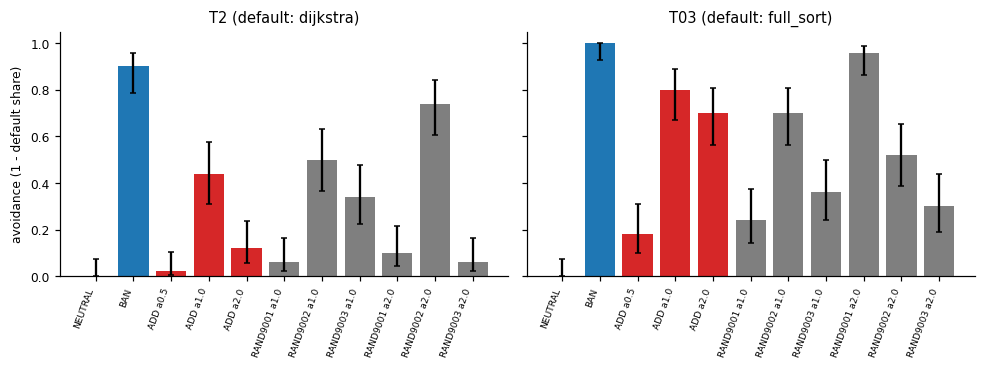

In [15]:
plt.rcParams.update({"font.size": 8, "pdf.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False})
plt.rcParams["figure.dpi"] = 110  # notebook display only
pal = {"NEUTRAL": "#9e9e9e", "BAN": "#1f77b4", "ADD": "#d62728", "RAND": "#7f7f7f", "SUB": "#2ca02c",
       "HEADS": "#9467bd"}


def col(a: str) -> str:
    for k, v in pal.items():
        if a.startswith(k):
            return v
    return "#333333"


def fig1_avoidance_by_arm(c2d: dict) -> None:
    # (1) avoidance by arm, per task
    tasks = [t for t in SAMPLED_TASKS if t in c2d["per_task"]]
    # original: plt.subplots(2, 3, figsize=(10, 5.5), sharey=True), one panel for each of the 6 sampled tasks
    fig, axes = plt.subplots(1, len(tasks), figsize=(4.5 * len(tasks), 3.4), sharey=True, squeeze=False)
    for ax, t in zip(axes.flat, tasks):
        arms = [a for a in ["NEUTRAL", "BAN", "ADD_a0.5", "ADD_a1.0", "ADD_a2.0", "RAND9001_a1.0", "RAND9002_a1.0",
                            "RAND9003_a1.0", "RAND9001_a2.0", "RAND9002_a2.0", "RAND9003_a2.0"]
                if a in c2d["per_task"][t]["arms"]]
        v = [c2d["per_task"][t]["arms"][a]["avoidance"] for a in arms]
        ci = [c2d["per_task"][t]["arms"][a]["avoidance_ci95"] for a in arms]
        err = np.array([[max(0, x - c[0]) for x, c in zip(v, ci)], [max(0, c[1] - x) for x, c in zip(v, ci)]])
        ax.bar(range(len(arms)), v, color=[col(a) for a in arms], yerr=err, capsize=2)
        ax.set_xticks(range(len(arms)))
        ax.set_xticklabels([a.replace("_a", " a") for a in arms], rotation=70, ha="right", fontsize=6)
        ax.set_title(f"{t} (default: {DEFAULT[t]})")
        ax.set_ylim(0, 1.05)
    axes[0, 0].set_ylabel("avoidance (1 - default share)")
    fig.tight_layout()
    plt.show()  # original: fig.savefig(FIG_DIR / "fig1_avoidance_by_arm.{png,pdf}", dpi=200); plt.close(fig)


fig1_avoidance_by_arm(c2d)

### Figure 2: where the non-default programs land

Each stacked bar is the composition of the *non-default* programs:
- the named ban;
- ADD at the α forecast in commit #2;
- the three α = 1 random directions pooled.

ADD can only count as reproducing the ban if it lands where the ban lands. Avoiding the default by switching to some other algorithm is not enough.

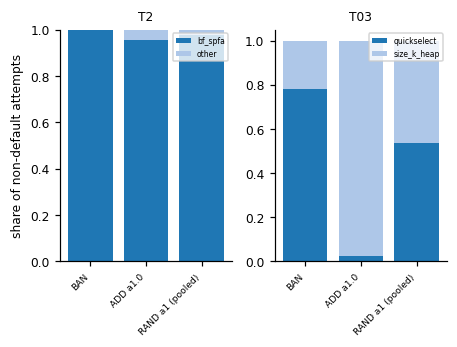

In [16]:
def fig2_landing_composition(c2d: dict) -> None:
    tasks = [t for t in SAMPLED_TASKS if t in c2d["per_task"]]
    # (2) landing composition ADD (best alpha) vs BAN vs RAND alpha 1 pooled
    fig, axes = plt.subplots(1, len(tasks), figsize=(2.1 * len(tasks), 3.2))
    for ax, t in zip(np.atleast_1d(axes), tasks):
        pt = c2d["per_task"][t]
        ba = (pt.get("forecast") or {}).get("best_alpha") or 1.0
        rows = {"BAN": pt["arms"].get("BAN", {}).get("landing", {}), f"ADD a{ba}": pt["arms"].get(f"ADD_a{ba}", {}).get("landing", {})}
        pooled: Counter = Counter()
        for s in (9001, 9002, 9003):
            pooled.update(pt["arms"].get(f"RAND{s}_a1.0", {}).get("landing", {}))
        rows["RAND a1 (pooled)"] = dict(pooled)
        labs = sorted({l for d in rows.values() for l in d})
        bottom = np.zeros(len(rows))
        cm = plt.get_cmap("tab20")
        for i, l in enumerate(labs):
            vals = np.array([d.get(l, 0) / max(sum(d.values()), 1) for d in rows.values()])
            ax.bar(range(len(rows)), vals, bottom=bottom, color=cm(i % 20), label=l)
            bottom += vals
        ax.set_xticks(range(len(rows)))
        ax.set_xticklabels(list(rows), rotation=45, ha="right", fontsize=6)
        ax.set_title(t, fontsize=8)
        ax.legend(fontsize=5, loc="upper right")
    np.atleast_1d(axes)[0].set_ylabel("share of non-default attempts")
    fig.tight_layout()
    plt.show()  # original: fig.savefig(FIG_DIR / "fig2_landing_composition.{png,pdf}", dpi=200); plt.close(fig)


fig2_landing_composition(c2d)

### Figure 3: SUBTRACT, the necessity test

Each point is Δ = banned share(SUB arm) − banned share(BAN) on the same CRN slots, with its 95% paired-bootstrap CI. If `v` carried the prohibition, projecting it out of the ban prompt would bring the default back. The frozen bar for the pooled effect is Δ ≥ 0.3 (red dashed line) with a CI above 0. `SUB_affine` and `SUB_rand9001` were run only on the path tasks (T1/T2).

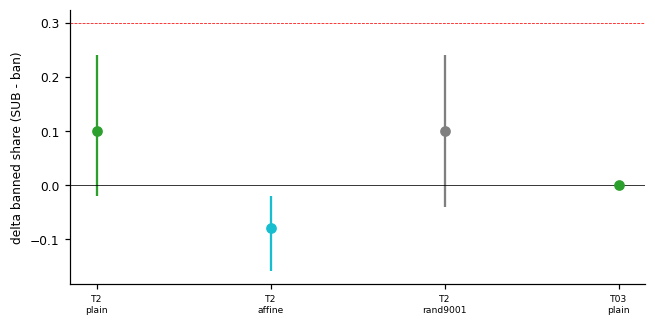

In [17]:
def fig3_subtract(c2d: dict) -> None:
    tasks = [t for t in SAMPLED_TASKS if t in c2d["per_task"]]
    # (3) SUBTRACT panel
    fig, ax = plt.subplots(figsize=(6, 3))
    xs, labels = 0, []
    for t in tasks:
        for arm in ("SUB_plain", "SUB_affine", "SUB_rand9001"):
            s = c2d["per_task"][t]["subtract"].get(arm)
            if not s:
                continue
            ax.errorbar(xs, s["delta_banned_share"], yerr=[[s["delta_banned_share"] - s["ci95"][0]],
                                                           [s["ci95"][1] - s["delta_banned_share"]]],
                        fmt="o", color={"SUB_plain": "#2ca02c", "SUB_affine": "#17becf", "SUB_rand9001": "#7f7f7f"}[arm])
            labels.append(f"{t}\n{arm.replace('SUB_', '')}")
            xs += 1
    ax.axhline(0, color="k", lw=0.5)
    ax.axhline(0.3, color="r", lw=0.5, ls="--")
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=6)
    ax.set_ylabel("delta banned share (SUB - ban)")
    fig.tight_layout()
    plt.show()  # original: fig.savefig(FIG_DIR / "fig3_subtract.{png,pdf}", dpi=200); plt.close(fig)


fig3_subtract(c2d)

### Figure 9 (exploratory): `v` against 15 random directions

Grey dots are the 15 random directions at α = 1: the 3 frozen seeds plus 12 exploratory seeds of the same construction, all on slots k 0–9. The red diamond is ADD. If `v` were a special "prohibition" direction, it should stand clearly above the grey cloud on every task.

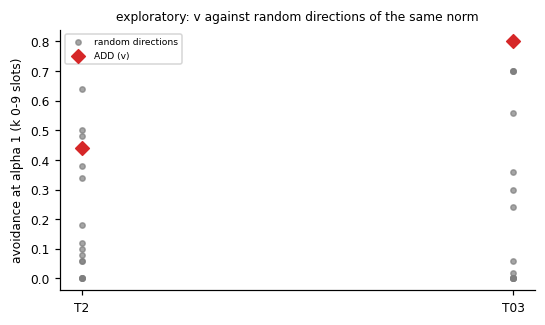

In [18]:
def fig9_random_distribution(c2d: dict) -> None:
    # (9) exploratory: ADD alpha 1 against the distribution of random directions
    erd = c2d.get("exploratory_random_distribution") or {}
    if erd:
        fig, ax = plt.subplots(figsize=(5, 3))
        for i, (t, v) in enumerate(erd.items()):
            vals = list(v["random_avoidance"].values())
            ax.scatter([i] * len(vals), vals, color="#7f7f7f", s=12, alpha=0.7, label="random directions" if i == 0 else None)
            ax.scatter([i], [v["add_avoidance_k0_9"]], color="#d62728", s=40, marker="D", label="ADD (v)" if i == 0 else None)
        ax.set_xticks(range(len(erd)))
        ax.set_xticklabels(list(erd))
        ax.set_ylabel("avoidance at alpha 1 (k 0-9 slots)")
        ax.set_title("exploratory: v against random directions of the same norm", fontsize=8)
        ax.legend(fontsize=6)
        fig.tight_layout()
        plt.show()  # original: fig.savefig(FIG_DIR / "fig9_random_distribution.{png,pdf}", dpi=200); plt.close(fig)


fig9_random_distribution(c2d)

## Results summary

The last cell has four parts:
- **(a)** the decision quantities of every analysed task in one table;
- **(b)** each ADD-vs-random McNemar test;
- **(c)** two plots that check the demo subset against the full run (all 660 slots of the 6 tasks, from `metadata.full_run_reference`):
  - **left**: each arm's avoidance in the demo against the full run. With `K_SLOTS = 10`, the arms sampled only on slots k 0–9 sit on the diagonal (RANDOM, ADD α 0.5 and α 2, SUB_affine, SUB_rand9001). The black-edged arms (BAN, NEUTRAL, SUB_plain, ADD α 1) also had slots k 10–19 in the full run, so they can move;
  - **right**: the Holm-adjusted p-values of ADD versus each random control. These tests use exactly the slots k 0–9, so with `K_SLOTS = 10` they reproduce the full run;
- **(d)** the C2d verdict on the demo next to the full-run verdict. The other three claims are quoted from the full run, not recomputed.

C2d decision quantities on the demo subset:


,T2 (default dijkstra),T03 (default full_sort)
event gate passed,True,True
BAN avoidance,0.90,1.00
BAN lands on,bf_spfa,quickselect
ADD avoidance a1 / a2,0.44 / 0.12,0.80 / 0.70
RAND avoidance a1 (3 seeds),"0.06, 0.50, 0.34","0.24, 0.70, 0.36"
RAND avoidance a2 (3 seeds),"0.10, 0.74, 0.06","0.96, 0.52, 0.30"
ADD a1 lands on,bf_spfa,size_k_heap
"ADD above max RAND (a1, a2)","[False, False]","[True, False]"
ADD within random range,True,False
"JS(ADD, BAN) / null q95",0.023 / 0.023,0.508 / 0.034


ADD vs RANDOM on the same CRN slots (k 0-9):


,task,alpha,RAND seed,ADD avoid,RAND avoid,n10 (only ADD avoids),n01 (only RAND avoids),p one-sided,p Holm (demo),p Holm (full run)
0,T2,1.0,9001,0.44,0.06,21,2,0.0000,0.0002,0.0002
1,T2,1.0,9002,0.44,0.50,9,12,0.8083,1.0000,1.0000
2,T2,1.0,9003,0.44,0.34,15,10,0.2122,1.0000,1.0000
3,T2,2.0,9001,0.12,0.10,5,4,0.5000,1.0000,1.0000
4,T2,2.0,9002,0.12,0.74,0,31,1.0000,1.0000,1.0000
5,T2,2.0,9003,0.12,0.06,6,3,0.2539,1.0000,1.0000
6,T03,1.0,9001,0.80,0.24,28,0,0.0000,0.0000,0.0000
7,T03,1.0,9002,0.80,0.70,10,5,0.1509,0.3018,0.3018
8,T03,1.0,9003,0.80,0.36,22,0,0.0000,0.0000,0.0000
9,T03,2.0,9001,0.70,0.96,1,14,1.0000,1.0000,1.0000


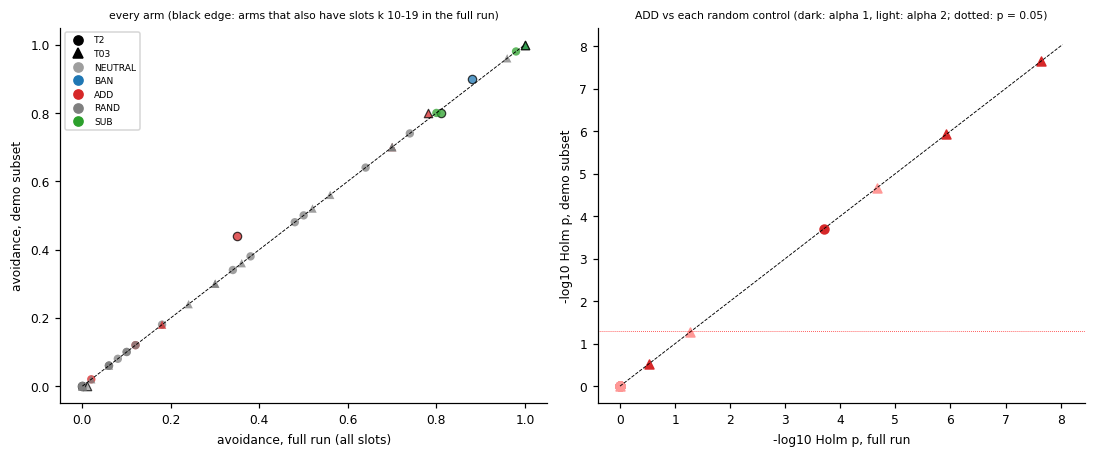

C2d verdict, demo subset (T2, T03; 2500 programs): DISCONFIRMED
  gated tasks ['T2', 'T03'], ADD passes on 0, within random range on ['T2']; pooled SUBTRACT delta 0.050 [0.000, 0.100] over ['T2', 'T03']
C2d verdict, full run (6 tasks, 660 slots): DISCONFIRMED
  gated tasks ['T2', 'T1', 'T03', 'T06', 'T05'], ADD passes on 0, within random range on ['T2', 'T1', 'T04', 'T06', 'T05']; pooled SUBTRACT delta -0.026 [-0.070, 0.028]
Other claims (full run): C2e locus on no task; C2f NOT SUPPORTED (delta T1 +0.06, T2 -0.03); 0g frozen rule passes: True


In [19]:
# ---------------------------------------------------------------- results summary (demo subset vs the full run)
ref = data["metadata"]["full_run_reference"]


def _f(x, nd=2):
    return "-" if x is None or (isinstance(x, float) and math.isnan(x)) else f"{x:.{nd}f}"


# (a) the decision quantities of the frozen C2d rule, one column per task
summary = {}
for t, v in c2d["per_task"].items():
    A, sub, js = v["arms"], v["subtract"].get("SUB_plain"), v.get("js_add_vs_ban") or {}
    erd = c2d["exploratory_random_distribution"].get(t, {})
    summary[f"{t} (default {DEFAULT[t]})"] = {
        "event gate passed": v["event_gate"]["pass"],
        "BAN avoidance": _f(A.get("BAN", {}).get("avoidance")),
        "BAN lands on": A.get("BAN", {}).get("modal_nondefault"),
        "ADD avoidance a1 / a2": f"{_f(A.get('ADD_a1.0', {}).get('avoidance'))} / "
                                 f"{_f(A.get('ADD_a2.0', {}).get('avoidance'))}",
        "RAND avoidance a1 (3 seeds)": ", ".join(_f(A.get(f"RAND{s}_a1.0", {}).get("avoidance")) for s in RAND_SEEDS),
        "RAND avoidance a2 (3 seeds)": ", ".join(_f(A.get(f"RAND{s}_a2.0", {}).get("avoidance")) for s in RAND_SEEDS),
        "ADD a1 lands on": A.get("ADD_a1.0", {}).get("modal_nondefault"),
        "ADD above max RAND (a1, a2)": str(list(v["add_above_max_rand"].values())),
        "ADD within random range": v["add_within_random_range"],
        "JS(ADD, BAN) / null q95": f"{_f(js.get('js'), 3)} / {_f(js.get('null_q95'), 3)}",
        "SUB_plain delta [95% CI]": (f"{_f(sub['delta_banned_share'])} [{_f(sub['ci95'][0])}, {_f(sub['ci95'][1])}]"
                                     if sub else "-"),
        "ADD passes (frozen rule)": v["add_pass"],
        "ADD percentile among 15 RAND (expl.)": _f(erd.get("add_percentile_among_random")),
    }
print("C2d decision quantities on the demo subset:")
display(pd.DataFrame(summary))

# (b) ADD vs each frozen random control: exact one-sided McNemar on the CRN flip table, Holm over the 6 tests
tests = []
for t, v in c2d["per_task"].items():
    full = {(x["alpha"], x["seed"]): x for x in ref["per_task_detail"].get(t, {}).get("add_vs_rand", [])}
    for x in v["add_vs_rand"]:
        tests.append({"task": t, "alpha": x["alpha"], "RAND seed": x["seed"], "ADD avoid": x["add_avoid"],
                      "RAND avoid": x["rand_avoid"], "n10 (only ADD avoids)": x["n10"],
                      "n01 (only RAND avoids)": x["n01"], "p one-sided": x["p_one_sided"],
                      "p Holm (demo)": x["p_holm"],
                      "p Holm (full run)": full.get((x["alpha"], x["seed"]), {}).get("p_holm")})
print("ADD vs RANDOM on the same CRN slots (k 0-9):")
display(pd.DataFrame(tests).round(4))

# (c) does the demo subset reproduce the full 660-slot run?
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
marks = dict(zip(SAMPLED_TASKS, ("o", "s", "^", "D", "v", "P")))
ax = axes[0]
for t, v in c2d["per_task"].items():
    full_av = ref["per_task_avoidance"].get(t, {})
    for a, s in v["arms"].items():
        if full_av.get(a) is None or math.isnan(s["avoidance"]):
            continue
        ax.scatter(full_av[a], s["avoidance"], marker=marks[t], color=col(a), s=30, alpha=0.75,
                   edgecolors="k" if a in ("BAN", "NEUTRAL", "SUB_plain", "ADD_a1.0") else "none", linewidths=0.8)
ax.plot([0, 1], [0, 1], "k--", lw=0.6)
ax.set_xlabel("avoidance, full run (all slots)")
ax.set_ylabel("avoidance, demo subset")
ax.set_title("every arm (black edge: arms that also have slots k 10-19 in the full run)", fontsize=7)
handles = [plt.Line2D([], [], marker=marks[t], ls="", color="k", label=t) for t in c2d["per_task"]]
handles += [plt.Line2D([], [], marker="o", ls="", color=c, label=k) for k, c in pal.items() if k != "HEADS"]
ax.legend(handles=handles, fontsize=6, loc="upper left")
ax = axes[1]
for x in tests:
    if x["p Holm (full run)"] is None:
        continue
    ax.scatter(-np.log10(max(x["p Holm (full run)"], 1e-12)), -np.log10(max(x["p Holm (demo)"], 1e-12)),
               marker=marks[x["task"]], color="#d62728" if x["alpha"] == 1.0 else "#ff9896", s=34)
lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, lim], [0, lim], "k--", lw=0.6)
ax.axhline(-np.log10(0.05), color="r", lw=0.5, ls=":")
ax.set_xlabel("-log10 Holm p, full run")
ax.set_ylabel("-log10 Holm p, demo subset")
ax.set_title("ADD vs each random control (dark: alpha 1, light: alpha 2; dotted: p = 0.05)", fontsize=7)
fig.tight_layout()
plt.show()

# (d) the verdict, demo subset vs full run (C2e / C2f / 0g are quoted from the full run, not recomputed)
c, ps = ref["c2d"], c2d["pooled_subtract"]
ci = ps.get("ci95_task_bootstrap")
print(f"C2d verdict, demo subset ({', '.join(c2d['per_task'])}; {len(rows)} programs): {c2d['verdict']}")
print(f"  gated tasks {c2d['denominator_tasks']}, ADD passes on {c2d['n_add_pass']}, within random range on "
      f"{c2d['tasks_add_within_random_range']}; pooled SUBTRACT delta {_f(ps['delta'], 3)} "
      f"[{_f(ci[0], 3) if ci else '-'}, {_f(ci[1], 3) if ci else '-'}] over {ps['tasks']}")
print(f"C2d verdict, full run (6 tasks, 660 slots): {c['verdict']}")
print(f"  gated tasks {c['denominator_tasks']}, ADD passes on {c['n_add_pass']}, within random range on "
      f"{c['within_random_range']}; pooled SUBTRACT delta {_f(c['pooled_subtract']['delta'], 3)} "
      f"[{_f(c['pooled_subtract']['ci95_task_bootstrap'][0], 3)}, {_f(c['pooled_subtract']['ci95_task_bootstrap'][1], 3)}]")
o = ref["other_claims"]
print(f"Other claims (full run): C2e locus on {[t for t, v in o['c2e'].items() if v['locus']] or 'no task'}; "
      f"C2f {o['c2f']['verdict']} (delta T1 {o['c2f']['delta_T1']:+.2f}, T2 {o['c2f']['delta_T2']:+.2f}); "
      f"0g frozen rule passes: {o['zero_g_frozen_pass_any_layer']}")

## Takeaways

**On the 100-slot demo subset, the frozen C2d rule gives the full run's verdict: DISCONFIRMED.**

- **T2 (default Dijkstra).**
  - The named ban works: avoidance is 0.90, and every non-default program uses Bellman-Ford/SPFA.
  - Writing `v` into the neutral prompt (ADD, α = 1) raises avoidance from 0.00 to 0.44, and ADD also lands on Bellman-Ford/SPFA.
  - But one of the three norm-matched random directions moves the model as much (RAND9002: 0.50), and after Holm correction ADD beats only one of the three. ADD is therefore *within the random range*.
  - The dose-response is not monotone (α 0.5 / 1 / 2 → 0.02 / 0.44 / 0.12). Among 15 random directions, ADD sits at the 80th percentile.
- **T03 (default full sort).**
  - At α = 1, ADD's raw avoidance (0.80) is above the three frozen controls (≤ 0.70) and above all 15 random directions.
  - It still does not reproduce the ban. ADD lands on a size-k heap (39 of 40 non-default programs) while the ban lands on quickselect (39 of 50). The landing JS divergence is 0.51 against a permutation q95 of 0.03, and the forecast committed before the ban arms were sampled (size-k heap) missed the ban's modal landing.
  - ADD also misses Holm significance against RAND9002 (p = 0.30). `v` acts as a direction-specific push, not as the ban.
- **SUBTRACT.** Projecting `v` out of the ban prompt does not bring the default back:
  - on T2, SUB_plain gives Δ = +0.10 [−0.02, 0.24], the same as the random edit SUB_rand9001 (+0.10), and the twin-anchored SUB_affine goes the other way (−0.08);
  - on T03, Δ = 0.00;
  - the pooled Δ = 0.05 is far below the frozen bar of 0.3.
- **Agreement with the full run.**
  - Every ADD-vs-random McNemar/Holm test matches the full run exactly, because those arms were sampled only on slots k 0–9.
  - The arms that had 100 slots in the full run (BAN, NEUTRAL, SUB_plain, ADD α 1) differ by at most about 0.09. The largest gap is T2 ADD α 1: 0.44 here against 0.35 over all 100 slots.

**Reproducing the full run with this notebook.** Fed all 660 slots of the `c2d_arms` dataset, the code above reproduces the artifact's `results/c2d.json` exactly. Every number matched in a check run while this notebook was built; only the realised-norm diagnostic and the head-ablation arm summaries were left out, since neither is in this dataset. To repeat it:
1. load `full_method_out.json` from the artifact folder instead of `mini_demo_data.json`;
2. add `predictions/c2d_landings.json` to the loaded data as `data["metadata"]["c2d_landings"]`;
3. set `TASKS = SAMPLED_TASKS` and `K_SLOTS = 10**9`.

The full 6-task result is DISCONFIRMED: ADD passes on 0 of 5 gated tasks and is within the random range on 5 of 6, and the pooled SUBTRACT Δ is −0.026 [−0.07, 0.03]. Regenerating the labels themselves requires the GPU stages of `method.py` (Qwen3-8B on an FP8-capable GPU, about 3.5 GPU-hours).